In [2]:
!pip -q install nltk scikit-learn ipywidgets

import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

name = "Nikhil Sharma"
roll_no = "1024170220"

print(name, roll_no)

Nikhil Sharma 1024170220


In [3]:
data = {
    "symptoms": [
        "What are the symptoms of heart disease?",
        "Why do I have chest pain?",
        "Is shortness of breath a heart problem?",
        "What does an irregular heartbeat mean?",
        "Can heart disease cause dizziness?",
        "Why does my heart beat very fast?",
        "What are warning signs of a heart attack?",
        "Can heart problems cause tiredness?"
    ],
    "prevention": [
        "How can I prevent heart disease?",
        "How do I keep my heart healthy?",
        "Does exercise prevent heart problems?",
        "How can I reduce my heart disease risk?",
        "Is quitting smoking good for my heart?",
        "How do I improve cardiovascular health?",
        "Can better sleep protect the heart?",
        "What habits prevent heart attacks?"
    ],
    "diet": [
        "What foods are good for the heart?",
        "Is salt bad for heart health?",
        "What diet should heart patients follow?",
        "Are vegetables good for the heart?",
        "Should I avoid saturated fats?",
        "Does eating fish help heart health?",
        "What foods increase cholesterol?",
        "Is a Mediterranean diet heart healthy?"
    ],
    "exercise": [
        "What exercises are good for the heart?",
        "How much should I walk daily?",
        "Is running good for cardiovascular health?",
        "Can I do yoga for heart health?",
        "How much exercise does the heart need?",
        "Is cycling a good cardio exercise?",
        "Does swimming improve heart fitness?",
        "What is moderate intensity exercise?"
    ],
    "risk_factors": [
        "What causes heart disease?",
        "Does smoking increase heart attack risk?",
        "Is high blood pressure dangerous?",
        "Can diabetes cause heart problems?",
        "Does obesity affect heart health?",
        "Is high cholesterol a risk factor?",
        "Can stress increase heart disease risk?",
        "Does family history affect heart disease?"
    ],
    "treatment": [
        "How is heart disease treated?",
        "What medicines treat high blood pressure?",
        "Can heart disease be cured?",
        "What is angioplasty?",
        "When is bypass surgery needed?",
        "What are statins used for?",
        "How do doctors treat blocked arteries?",
        "What is cardiac rehabilitation?"
    ]
}

queries = []
labels = []

for intent, questions in data.items():
    for question in questions:
        queries.append(question)
        labels.append(intent)

df = pd.DataFrame({"query": queries, "intent": labels})

print("Total queries:", len(df))
print(df["intent"].value_counts())
df.head()

Total queries: 48
intent
symptoms        8
prevention      8
diet            8
exercise        8
risk_factors    8
treatment       8
Name: count, dtype: int64


,query,intent
0,What are the symptoms of heart disease?,symptoms
1,Why do I have chest pain?,symptoms
2,Is shortness of breath a heart problem?,symptoms
3,What does an irregular heartbeat mean?,symptoms
4,Can heart disease cause dizziness?,symptoms


In [4]:
taxonomy = {
    "Heart Conditions": {
        "Symptoms": ["Chest pain", "Breathlessness"],
        "Treatment": ["Medication", "Surgery"]
    },
    "Healthy Lifestyle": {
        "Diet": ["Low salt diet", "Healthy fats"],
        "Exercise": ["Walking", "Cycling"]
    },
    "Risk Management": {
        "Risk Factors": ["High blood pressure", "Smoking"],
        "Prevention": ["Regular checkups", "Avoid tobacco"]
    },
    "Heart Monitoring": {
        "Vital Signs": ["Blood pressure", "Heart rate"],
        "Tests": ["ECG", "Echocardiogram"]
    }
}

for category, subcategories in taxonomy.items():
    print(category)
    for sub, items in subcategories.items():
        print("  ", sub, ":", ", ".join(items))

Heart Conditions
   Symptoms : Chest pain, Breathlessness
   Treatment : Medication, Surgery
Healthy Lifestyle
   Diet : Low salt diet, Healthy fats
   Exercise : Walking, Cycling
Risk Management
   Risk Factors : High blood pressure, Smoking
   Prevention : Regular checkups, Avoid tobacco
Heart Monitoring
   Vital Signs : Blood pressure, Heart rate
   Tests : ECG, Echocardiogram


In [5]:
concepts = [
    "Heart", "Blood Pressure", "Cholesterol", "Smoking",
    "Exercise", "Healthy Diet", "Heart Disease", "Diabetes",
    "Obesity", "ECG"
]

relationships = [
    ("Smoking", "increases risk of", "Heart Disease"),
    ("Blood Pressure", "affects", "Heart"),
    ("Cholesterol", "can contribute to", "Heart Disease"),
    ("Exercise", "helps prevent", "Heart Disease"),
    ("Healthy Diet", "helps manage", "Cholesterol"),
    ("Diabetes", "increases risk of", "Heart Disease"),
    ("Obesity", "increases risk of", "Heart Disease"),
    ("ECG", "measures electrical activity of", "Heart"),
    ("Exercise", "helps manage", "Blood Pressure"),
    ("Healthy Diet", "supports", "Heart"),
    ("Smoking", "damages", "Heart"),
    ("Obesity", "is associated with", "Blood Pressure")
]

print("Concepts:", len(concepts))
print("Relationships:", len(relationships))

for a, relation, b in relationships:
    print(a, "->", relation, "->", b)

Concepts: 10
Relationships: 12
Smoking -> increases risk of -> Heart Disease
Blood Pressure -> affects -> Heart
Cholesterol -> can contribute to -> Heart Disease
Exercise -> helps prevent -> Heart Disease
Healthy Diet -> helps manage -> Cholesterol
Diabetes -> increases risk of -> Heart Disease
Obesity -> increases risk of -> Heart Disease
ECG -> measures electrical activity of -> Heart
Exercise -> helps manage -> Blood Pressure
Healthy Diet -> supports -> Heart
Smoking -> damages -> Heart
Obesity -> is associated with -> Blood Pressure


In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word.isalpha()]
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(tokens)

df["processed"] = df["query"].apply(preprocess)

print("Original:", df["query"][0])
print("Processed:", df["processed"][0])

Original: What are the symptoms of heart disease?
Processed: symptom heart disease


In [7]:
X = df["processed"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

vectorizer = TfidfVectorizer(ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

print("Model trained successfully")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model trained successfully
Training samples: 36
Testing samples: 12


Accuracy: 0.3333333333333333
Precision: 0.2916666666666667
Recall: 0.3333333333333333
F1 Score: 0.3055555555555555

Classification Report:
              precision    recall  f1-score   support

        diet       0.00      0.00      0.00         2
    exercise       0.50      0.50      0.50         2
  prevention       0.50      0.50      0.50         2
risk_factors       0.25      0.50      0.33         2
    symptoms       0.00      0.00      0.00         2
   treatment       0.50      0.50      0.50         2

    accuracy                           0.33        12
   macro avg       0.29      0.33      0.31        12
weighted avg       0.29      0.33      0.31        12



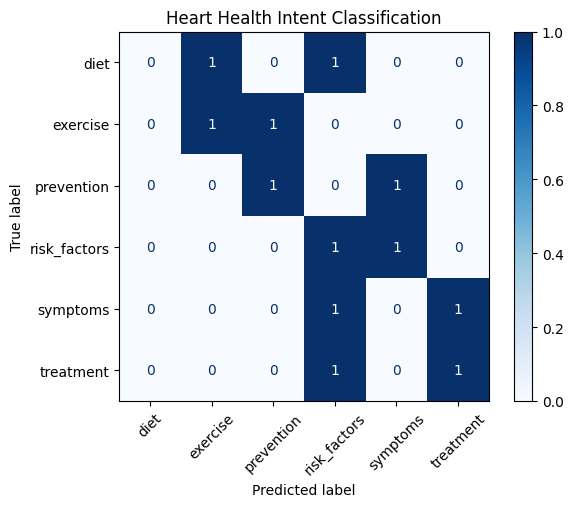

In [8]:
y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=45, cmap="Blues"
)
plt.title("Heart Health Intent Classification")
plt.show()

In [9]:
knowledge_base = {
    "symptoms": "Heart problems may cause chest discomfort, breathlessness, fatigue, dizziness or palpitations. Symptoms should be evaluated by a doctor.",

    "prevention": "Avoid tobacco, exercise regularly, eat a balanced diet, sleep well and monitor blood pressure and cholesterol.",

    "diet": "Choose fruits, vegetables, whole grains, nuts and healthy fats. Limit excess salt, saturated fats and highly processed foods.",

    "exercise": "Adults should generally aim for at least 150 minutes of moderate aerobic exercise weekly, if medically appropriate.",

    "risk_factors": "Major risk factors include high blood pressure, high cholesterol, diabetes, smoking, obesity and family history.",

    "treatment": "Treatment depends on the condition and may include lifestyle changes, medicines, angioplasty, bypass surgery or cardiac rehabilitation."
}

for intent, answer in knowledge_base.items():
    print(intent.upper())
    print(answer, "\n")

SYMPTOMS
Heart problems may cause chest discomfort, breathlessness, fatigue, dizziness or palpitations. Symptoms should be evaluated by a doctor. 

PREVENTION
Avoid tobacco, exercise regularly, eat a balanced diet, sleep well and monitor blood pressure and cholesterol. 

DIET
Choose fruits, vegetables, whole grains, nuts and healthy fats. Limit excess salt, saturated fats and highly processed foods. 

EXERCISE
Adults should generally aim for at least 150 minutes of moderate aerobic exercise weekly, if medically appropriate. 

RISK_FACTORS
Major risk factors include high blood pressure, high cholesterol, diabetes, smoking, obesity and family history. 

TREATMENT
Treatment depends on the condition and may include lifestyle changes, medicines, angioplasty, bypass surgery or cardiac rehabilitation. 



In [13]:
emergency_words = [
    "heart attack", "severe chest pain", "crushing chest pain",
    "fainted", "unconscious", "cannot breathe", "can't breathe",
    "chest pain and sweating", "chest pain and breathlessness"
]

heart_words = [
    "heart", "cardiac", "chest", "blood pressure", "cholesterol",
    "smoking", "exercise", "walking", "running", "diet",
    "food", "salt", "fat", "diabetes", "obesity", "artery",
    "angioplasty", "bypass", "statin", "cardiovascular",
    "heartbeat", "pulse", "ecg", "breathlessness",
    "breath", "hypertension", "yoga", "swimming",
    "cycling", "stress", "sleep"
]

def assistant(query):
    query_lower = query.lower().strip()


    if not query_lower:
        return "Please enter a question."

    if any(word in query_lower for word in emergency_words):
        return "EMERGENCY: Seek immediate medical help. Call 112 in India. Do not delay."

    if not any(word in query_lower for word in heart_words):
        return "Unsupported query. Please ask about heart health."

    processed = preprocess(query)
    features = vectorizer.transform([processed])

    probabilities = model.predict_proba(features)[0]
    confidence = max(probabilities)
    intent = model.classes_[np.argmax(probabilities)]

    if confidence < 0.1:
        return "Low confidence. Please rephrase your heart health question."

    answer = knowledge_base.get(intent)

    if answer is None:
        return "Information is currently unavailable."

    if intent == "treatment":
        answer += " Do not start or stop medication without medical advice."

    return f"Intent: {intent}\nConfidence: {confidence:.2f}\nResponse: {answer}"

In [14]:
test_queries = [
    "What are symptoms of heart disease?",
    "How can I prevent heart disease?",
    "What should I eat for heart health?",
    "Is walking good for the heart?",
    "Does smoking increase heart disease risk?",
    "How is heart disease treated?",
    "How do I make my heart healthier?",
    "How do I treat kidney stones?",
    "Tell me about cardiac quantum bananas",
    "I have severe chest pain and cannot breathe"
]

for i, query in enumerate(test_queries, 1):
    print("Test", i)
    print("Question:", query)
    print(assistant(query))
    print("-" * 50)

Test 1
Question: What are symptoms of heart disease?
Intent: symptoms
Confidence: 0.27
Response: Heart problems may cause chest discomfort, breathlessness, fatigue, dizziness or palpitations. Symptoms should be evaluated by a doctor.
--------------------------------------------------
Test 2
Question: How can I prevent heart disease?
Intent: prevention
Confidence: 0.29
Response: Avoid tobacco, exercise regularly, eat a balanced diet, sleep well and monitor blood pressure and cholesterol.
--------------------------------------------------
Test 3
Question: What should I eat for heart health?
Intent: diet
Confidence: 0.23
Response: Choose fruits, vegetables, whole grains, nuts and healthy fats. Limit excess salt, saturated fats and highly processed foods.
--------------------------------------------------
Test 4
Question: Is walking good for the heart?
Intent: exercise
Confidence: 0.24
Response: Adults should generally aim for at least 150 minutes of moderate aerobic exercise weekly, if me

In [12]:
import ipywidgets as widgets
from IPython.display import display, clear_output

print("Heart Health Information Assistant")
print("Name:", name)
print("Roll No:", roll_no)
print("Enter multiple questions, one per line.\n")

input_box = widgets.Textarea(
    placeholder="Enter your questions here...",
    layout=widgets.Layout(width="600px", height="120px")
)

button = widgets.Button(description="Ask Assistant")
output = widgets.Output()

def on_click(b):
    with output:
        clear_output()
        questions = input_box.value.split("\n")

        for question in questions:
            if question.strip():
                print("You:", question)
                print("Assistant:", assistant(question))
                print("-" * 50)

button.on_click(on_click)

display(input_box, button, output)

Heart Health Information Assistant
Name: Nikhil Sharma
Roll No: 1024170220
Enter multiple questions, one per line.



Textarea(value='', layout=Layout(height='120px', width='600px'), placeholder='Enter your questions here...')

Button(description='Ask Assistant', style=ButtonStyle())

Output()